# 10 · Explaining Models — Why Did the Model Say That?

A churn model that says "customer #4821: 87% risk" is only half useful. The retention team wants to know **why** (so they know what to offer), managers want to know **what drives churn overall**, and regulators may require explanations for decisions about people. Explanations are also your best tool for **catching bugs and leakage** — a model that leans on a feature it shouldn't is a red flag.

**What you'll learn**
1. Kinds of explanation: **global vs local**, **glass-box vs black-box**, model-specific vs model-agnostic
2. Reading a glass-box model: logistic-regression coefficients and **odds ratios**
3. **Permutation importance** — 🐍 pure Python → 🔢 NumPy → 📦 scikit-learn
4. **Partial dependence (PDP) and ICE curves** — how predictions change as one feature moves
5. **Shapley values / SHAP** — fair credit for every feature in every prediction: exact computation 🐍 from scratch, a 🔢 sampling approximation, then the 📦 `shap` library
6. **LIME** from scratch — explaining one prediction with a local linear model
7. The pitfalls: correlated features, explanation ≠ causation

Bonus: our dataset was generated from a **known formula** (see `data/make_churn_data.py`), so we can check whether the explanations find the *true* drivers. The truth: contract type, tenure (non-linear, flattening after ~3 years), support calls, satisfaction, days since last login, monthly charges, electronic-check payment, an interaction "expensive **and** new", and partner status. **Age, region and session minutes have no effect.**

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import math, random, itertools, warnings
plt.rcParams["figure.figsize"] = (5.5, 3.6)
plt.rcParams["axes.grid"] = True; plt.rcParams["grid.alpha"] = 0.3
warnings.filterwarnings("ignore", message="IProgress not found")

from churn_utils import load_clean, CATEGORICAL
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OrdinalEncoder
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score

df, X, y = load_clean(with_features=False)       # raw cleaned features only — simpler to explain
X = X.copy()
enc = OrdinalEncoder()
X[CATEGORICAL] = enc.fit_transform(X[CATEGORICAL])  # trees are happy with integer-coded categories
X = X.astype(float)                                 # all-float columns keep the plotting tools happy
cat_maps = {c: dict(enumerate(cats)) for c, cats in zip(CATEGORICAL, enc.categories_)}
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=0, stratify=y)

gbm = HistGradientBoostingClassifier(learning_rate=0.07, max_leaf_nodes=8, min_samples_leaf=100,
                                     max_iter=150, random_state=0).fit(X_train, y_train)
# (we keep categories as plain integer codes rather than using native categorical splits, because
#  shap's TreeExplainer computes exact values for ordinary numeric splits)
print(f"black-box model: gradient boosting, test AUC {roc_auc_score(y_test, gbm.predict_proba(X_test)[:, 1]):.3f}")
print("category codes:", cat_maps["contract"], cat_maps["payment_method"])

black-box model: gradient boosting, test AUC 0.822
category codes: {0: 'month-to-month', 1: 'one-year', 2: 'two-year'} {0: 'bank transfer', 1: 'credit card', 2: 'electronic check', 3: 'mailed check'}


## 1. A map of explanation methods

| | **Global** — how does the model behave overall? | **Local** — why *this* prediction? |
|---|---|---|
| **Glass-box** (the model *is* the explanation) | linear-model coefficients, a small tree's rules | coefficient × feature value |
| **Model-agnostic** (treat the model as a black box) | permutation importance, partial dependence | SHAP, LIME, ICE curves |

Model-agnostic methods only need `predict` — they work for *any* model, which is why we build them by hand below.

## 2. A glass-box model: logistic regression

With standardised inputs, each coefficient says how many units the **log-odds** of churn move when the feature rises by one standard deviation. Exponentiate it to get an **odds ratio**: ×1.5 means "50% higher odds of churning".

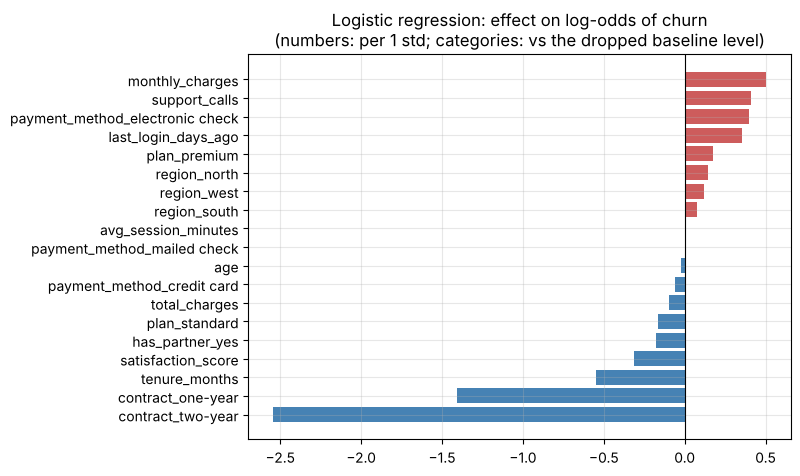

odds ratios for the biggest effects:
 support_calls        1.50
monthly_charges      1.66
tenure_months        0.58
contract_one-year    0.24
contract_two-year    0.08
dtype: float64


In [2]:
from sklearn.pipeline import make_pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression

Xr_train = df.drop(columns="churned").loc[X_train.index]       # un-encoded version for one-hot
numeric = [c for c in X.columns if c not in CATEGORICAL]
lr = make_pipeline(ColumnTransformer([("num", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), numeric),
                                       ("cat", OneHotEncoder(drop="first"), CATEGORICAL)]),
                   LogisticRegression(max_iter=2000)).fit(Xr_train, y_train)
names = [n.split("__")[1] for n in lr[0].get_feature_names_out()]
coef = pd.Series(lr[-1].coef_[0], index=names).sort_values()
plt.figure(figsize=(7, 5)); plt.barh(coef.index, coef.values, color=np.where(coef > 0, "indianred", "steelblue"))
plt.axvline(0, c="k", lw=0.8); plt.title("Logistic regression: effect on log-odds of churn\n(numbers: per 1 std; categories: vs the dropped baseline level)"); plt.show()
print("odds ratios for the biggest effects:\n", np.exp(coef[coef.abs().sort_values().index[-5:]]).round(2))

Clear and honest — but only as good as the model's assumptions. Logistic regression can't represent "churn falls fast then flattens with tenure" or the "expensive **and** new" interaction unless you engineer them. For flexible models we need other tools.

## 3. Permutation importance (global)

**Idea:** if a feature matters, scrambling it should hurt the model. So:
1. Score the model on validation data.
2. **Shuffle one column** (breaking its link to the target, while keeping its distribution).
3. Re-score. **Importance = score drop.** Repeat a few times and average.

Use **held-out** data — on training data, an overfit model shows importance for noise it memorised.

In [3]:
# 🐍 Pure Python permutation importance (works with any model that has predict_proba)
def auc_python(y_true, scores):
    """Rank-based AUC (equivalent to the Mann-Whitney statistic), O(n log n)."""
    order = sorted(range(len(scores)), key=lambda i: scores[i])
    ranks = [0.0] * len(scores); i = 0
    while i < len(order):                       # average ranks over ties
        j = i
        while j + 1 < len(order) and scores[order[j + 1]] == scores[order[i]]: j += 1
        for k in range(i, j + 1): ranks[order[k]] = (i + j) / 2 + 1
        i = j + 1
    n_pos = sum(y_true); n_neg = len(y_true) - n_pos
    return (sum(r for r, t in zip(ranks, y_true) if t == 1) - n_pos * (n_pos + 1) / 2) / (n_pos * n_neg)

def permutation_importance_python(model, X_df, y_true, n_repeats=3, seed=0):
    rnd = random.Random(seed); cols = list(X_df.columns)
    base = auc_python(list(y_true), list(model.predict_proba(X_df)[:, 1]))
    out = {}
    for c in cols:
        drops = []
        for _ in range(n_repeats):
            shuffled = X_df.copy(); vals = shuffled[c].tolist(); rnd.shuffle(vals); shuffled[c] = vals
            drops.append(base - auc_python(list(y_true), list(model.predict_proba(shuffled)[:, 1])))
        out[c] = sum(drops) / n_repeats
    return base, out

base, imp_py = permutation_importance_python(gbm, X_test, y_test)
print(f"baseline test AUC {base:.4f}")
print({k: round(float(v), 4) for k, v in sorted(imp_py.items(), key=lambda kv: -kv[1])[:6]})

baseline test AUC 0.8221
{'contract': 0.1178, 'tenure_months': 0.0524, 'monthly_charges': 0.0406, 'satisfaction_score': 0.0272, 'last_login_days_ago': 0.0218, 'support_calls': 0.0181}


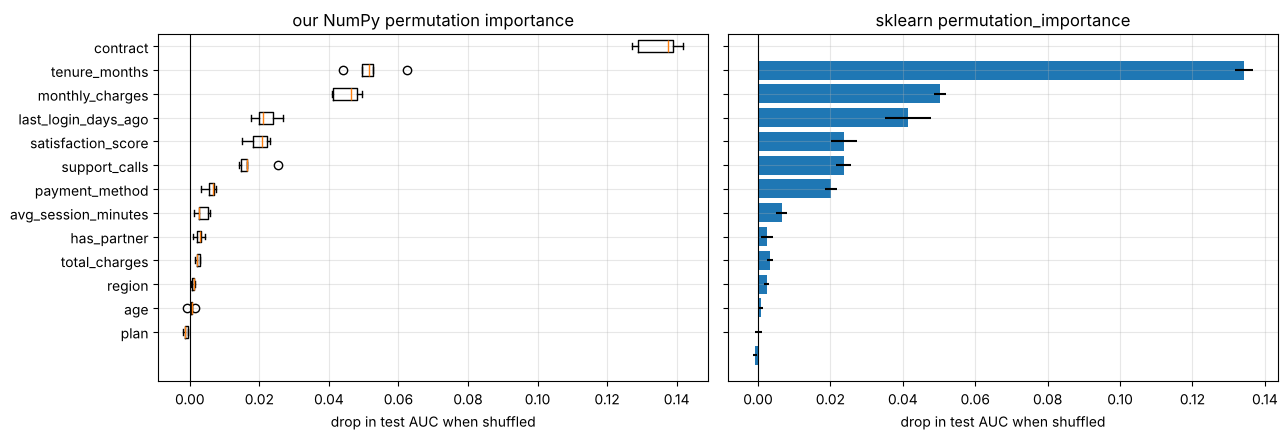

In [4]:
# 🔢 NumPy: shuffle with a permutation index; 📦 scikit-learn's version for comparison
def permutation_importance_numpy(model, X_arr, y_true, n_repeats=5, seed=0):
    rng = np.random.default_rng(seed)
    base = roc_auc_score(y_true, model.predict_proba(X_arr)[:, 1])
    imp = np.zeros((X_arr.shape[1], n_repeats))
    for j in range(X_arr.shape[1]):
        for r in range(n_repeats):
            Xp = X_arr.copy(); Xp[:, j] = Xp[rng.permutation(len(Xp)), j]
            imp[j, r] = base - roc_auc_score(y_true, model.predict_proba(Xp)[:, 1])
    return imp

import pandas as pd
class ArrayModel:                     # tiny adapter: lets our NumPy code call a model trained on a DataFrame
    def __init__(self, m, cols): self.m, self.cols = m, cols
    def predict_proba(self, A): return self.m.predict_proba(pd.DataFrame(A, columns=self.cols))

imp_np = permutation_importance_numpy(ArrayModel(gbm, X.columns), X_test.to_numpy(), y_test)
from sklearn.inspection import permutation_importance
imp_sk = permutation_importance(gbm, X_test, y_test, scoring="roc_auc", n_repeats=5, random_state=0)

order = np.argsort(imp_np.mean(1))
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
ax[0].boxplot(imp_np[order].T, orientation="horizontal", tick_labels=X.columns[order]); ax[0].set_title("our NumPy permutation importance")
ax[1].barh(X.columns[order], imp_sk.importances_mean[order], xerr=imp_sk.importances_std[order]); ax[1].set_title("sklearn permutation_importance")
for a in ax: a.axvline(0, c="k", lw=0.8); a.set_xlabel("drop in test AUC when shuffled")
plt.tight_layout(); plt.show()

✅ The top features (contract, tenure, support calls, satisfaction, last login…) match the true drivers, and **age, region and session minutes are ≈ 0** — correctly identified as irrelevant.

⚠️ **Correlated features share (and hide) importance.** `tenure_months` and `total_charges` are strongly correlated (r ≈ 0.78). The model can get tenure information from either, so shuffling *one* barely hurts — both can look less important than they are. Watch:

In [5]:
X_tr_dup = X_train.assign(tenure_copy=X_train["tenure_months"] + np.random.default_rng(0).normal(0, 0.5, len(X_train)))
X_te_dup = X_test.assign(tenure_copy=X_test["tenure_months"] + np.random.default_rng(1).normal(0, 0.5, len(X_test)))
gbm_dup = HistGradientBoostingClassifier(learning_rate=0.07, max_leaf_nodes=8, min_samples_leaf=100, max_iter=150, random_state=0).fit(X_tr_dup, y_train)
r = permutation_importance(gbm_dup, X_te_dup, y_test, scoring="roc_auc", n_repeats=5, random_state=0)
i_t, i_c = list(X_te_dup.columns).index("tenure_months"), list(X_te_dup.columns).index("tenure_copy")
print(f"original model:        tenure importance {imp_sk.importances_mean[list(X.columns).index('tenure_months')]:.4f}")
print(f"with a near-duplicate: tenure {r.importances_mean[i_t]:.4f} + copy {r.importances_mean[i_c]:.4f}  ← the credit is split")

original model:        tenure importance 0.0504
with a near-duplicate: tenure 0.0012 + copy 0.0327  ← the credit is split


**Remedies:** group correlated features and permute them together, or drop redundant features before interpreting.

## 4. Partial dependence (PDP) and ICE curves

Importance says *how much* a feature matters; **partial dependence** shows *how*. For feature $j$ and value $v$:
$$ \text{PD}_j(v) = \frac{1}{n}\sum_{i=1}^{n} f(\text{customer } i \text{ with feature } j \text{ set to } v) $$
"Set everyone's tenure to 5 months, average the predictions; now set it to 6…"

**ICE** (Individual Conditional Expectation) curves draw that line separately for each customer; the PDP is their average. If ICE lines have different *shapes*, the feature **interacts** with others.

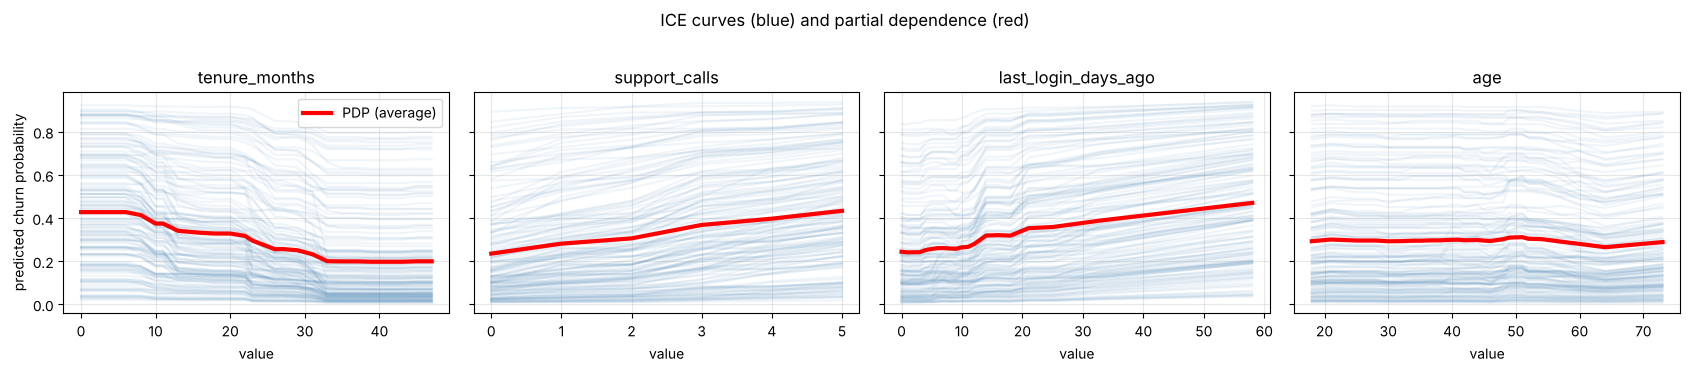

In [6]:
# 🔢 PDP + ICE from scratch
def ice_numpy(model, X_df, feature, grid, n_sample=150, seed=0):
    sample = X_df.sample(n_sample, random_state=seed)
    curves = np.zeros((n_sample, len(grid)))
    for g, v in enumerate(grid):
        Xv = sample.copy(); Xv[feature] = v
        curves[:, g] = model.predict_proba(Xv)[:, 1]
    return curves                     # PDP = curves.mean(0)

fig, axes = plt.subplots(1, 4, figsize=(17, 3.6), sharey=True)
for ax, f in zip(axes, ["tenure_months", "support_calls", "last_login_days_ago", "age"]):
    grid = np.unique(np.percentile(X_train[f].dropna(), np.linspace(1, 99, 25)))
    ice = ice_numpy(gbm, X_train, f, grid)
    ax.plot(grid, ice.T, c="steelblue", alpha=0.08); ax.plot(grid, ice.mean(0), c="r", lw=3, label="PDP (average)")
    ax.set_title(f); ax.set_xlabel("value")
axes[0].set_ylabel("predicted churn probability"); axes[0].legend(); plt.suptitle("ICE curves (blue) and partial dependence (red)", y=1.02)
plt.tight_layout(); plt.show()

- **tenure:** risk drops steeply over ~36 months then flattens — exactly the true `min(tenure, 36)` effect. A linear model couldn't show this.
- **support calls** and **last login:** risk rises; last login levels off around 40 days (true cap).
- **age:** flat — no effect. ✅

A **2-D PDP** shows interactions. The truth includes "monthly charges > 80 **and** tenure < 12 → extra risk":

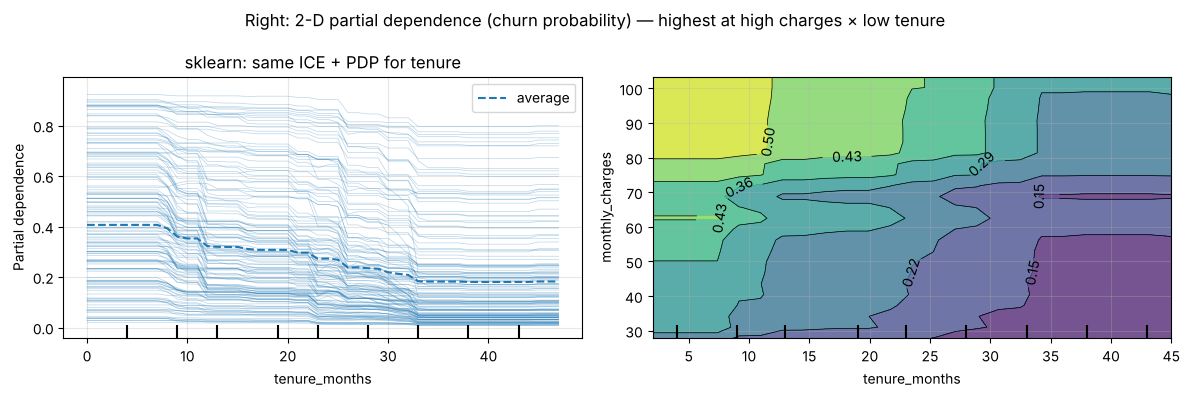

In [7]:
from sklearn.inspection import PartialDependenceDisplay
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
PartialDependenceDisplay.from_estimator(gbm, X_train, ["tenure_months"], kind="both", subsample=150, ax=ax[0], random_state=0, response_method="predict_proba")
ax[0].set_title("sklearn: same ICE + PDP for tenure")
PartialDependenceDisplay.from_estimator(gbm, X_train, [("tenure_months", "monthly_charges")], ax=ax[1], grid_resolution=25, response_method="predict_proba", method="brute")
plt.suptitle("Right: 2-D partial dependence (churn probability) — highest at high charges × low tenure"); plt.tight_layout(); plt.show()

⚠️ **PDP pitfall:** setting tenure to 2 months for a customer with $4,000 of total charges creates an *impossible* customer. With correlated features, PDPs average over unrealistic combinations. **ALE plots** (accumulated local effects) fix this by only comparing nearby, realistic values.

## 5. Shapley values and SHAP (local, and global by aggregation)

### 5.1 The idea, from game theory
Features are **players** cooperating to produce a **payout**: the prediction for one customer, compared with the average prediction. How do we split the credit fairly?

The **Shapley value** of feature $j$ = its **average marginal contribution** over every possible order in which features could "join the team":
$$ \phi_j = \sum_{S \subseteq F \setminus \{j\}} \frac{|S|!\,(|F|-|S|-1)!}{|F|!}\,\big[v(S \cup \{j\}) - v(S)\big] $$
where $v(S)$ is the model's prediction when only the features in $S$ are "known" (the others are averaged out over a background sample).

It's the **only** method with these fairness guarantees:
- **Additivity:** $\text{base value} + \sum_j \phi_j = \text{prediction}$ — the explanation adds up exactly.
- **Symmetry:** two features that contribute equally get equal credit.
- **Dummy:** a feature that never changes the output gets 0.

### 5.2 🐍 Exact Shapley values by brute force
The sum covers all $2^{|F|}$ subsets, so exact computation is only possible for a handful of features. We train a small 5-feature model and compute them exactly:

In [8]:
small_feats = ["contract", "tenure_months", "support_calls", "last_login_days_ago", "age"]
small = HistGradientBoostingClassifier(max_iter=100, max_leaf_nodes=8, random_state=0).fit(X_train[small_feats], y_train)
background = X_train[small_feats].sample(100, random_state=0)

def value_function(model, x, S, background):
    """v(S): average prediction (in log-odds) when features in S are fixed to x's values
    and the others take the background customers' values."""
    Xb = background.copy()
    for f in S:
        Xb[f] = x[f]
    return float(np.mean(model.decision_function(Xb)))

def exact_shapley_python(model, x, features, background):
    n = len(features); phi = {}
    for f in features:
        others = [g for g in features if g != f]; total = 0.0
        for size in range(n):
            for S in itertools.combinations(others, size):
                weight = math.factorial(size) * math.factorial(n - size - 1) / math.factorial(n)
                total += weight * (value_function(model, x, list(S) + [f], background) - value_function(model, x, list(S), background))
        phi[f] = total
    return phi

customer = X_test[small_feats].iloc[7]
phi = exact_shapley_python(small, customer, small_feats, background)
base_value = value_function(small, customer, [], background)
pred = small.decision_function(customer.to_frame().T)[0]
print("customer:", {k: (cat_maps['contract'][v] if k == 'contract' else v) for k, v in customer.items()})
for f, v in phi.items(): print(f"  φ[{f:20s}] = {v:+.3f}")
print(f"base {base_value:+.3f} + Σφ {sum(phi.values()):+.3f} = {base_value + sum(phi.values()):+.3f}   model log-odds {pred:+.3f}  ✔ additivity")

customer: {'contract': 'one-year', 'tenure_months': 36.0, 'support_calls': 2.0, 'last_login_days_ago': 21.0, 'age': 60.0}
  φ[contract            ] = -0.831
  φ[tenure_months       ] = -0.898
  φ[support_calls       ] = +0.196
  φ[last_login_days_ago ] = +0.358
  φ[age                 ] = -0.010
base -1.225 + Σφ -1.185 = -2.410   model log-odds -2.410  ✔ additivity


Each φ is in **log-odds**. Positive pushes toward churn, negative toward staying. "Age" gets ≈0 as it should (dummy property).

### 5.3 🔢 Sampling approximation
For 17 features, $2^{17}$ subsets × background is too slow. Instead, sample **random orderings** of the features; for each, add features one at a time and record each one's marginal contribution. The average converges to the exact Shapley value.

In [9]:
def shapley_sampling_numpy(model, x, features, background, n_perm=200, seed=0):
    rng = np.random.default_rng(seed); phi = np.zeros(len(features))
    bg = background[features].to_numpy(); xv = x[features].to_numpy()
    for _ in range(n_perm):
        order = rng.permutation(len(features))
        Xcur = bg.copy(); prev = model.decision_function(pd.DataFrame(Xcur, columns=features)).mean()
        for j in order:                                   # add features one by one in this random order
            Xcur[:, j] = xv[j]
            cur = model.decision_function(pd.DataFrame(Xcur, columns=features)).mean()
            phi[j] += cur - prev; prev = cur
    return phi / n_perm

phi_s = shapley_sampling_numpy(small, customer, small_feats, background)
print(pd.DataFrame({"exact": phi, "sampled (200 perms)": dict(zip(small_feats, phi_s))}).round(3))

                     exact  sampled (200 perms)
contract            -0.831               -0.844
tenure_months       -0.898               -0.897
support_calls        0.196                0.200
last_login_days_ago  0.358                0.368
age                 -0.010               -0.013


### 5.4 📦 The `shap` library
For tree models, **TreeSHAP** computes exact Shapley values in polynomial time by walking the trees — fast enough for millions of rows. (`shap.KernelExplainer` works for any model but is slow; `shap.LinearExplainer` handles linear models.)

In [10]:
import shap
explainer = shap.TreeExplainer(gbm)
sv = explainer(X_test)                        # Explanation object: .values, .base_values, .data
print("shape:", sv.values.shape, "| additivity holds:",
      np.allclose(sv.values.sum(1) + sv.base_values, gbm.decision_function(X_test), atol=1e-4))

shape: (1500, 13) | additivity holds: True


**Local explanation — one customer (waterfall plot).** Start from the base value (average log-odds), and each bar shows a feature pushing the prediction up (red) or down (blue).

customer 1080: predicted churn probability 0.93


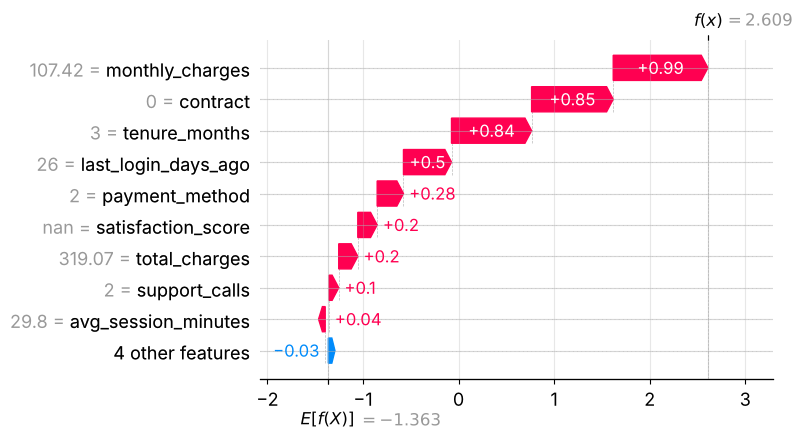

In [11]:
i = int(np.argmax(gbm.predict_proba(X_test)[:, 1]))           # the riskiest test customer
print(f"customer {X_test.index[i]}: predicted churn probability {gbm.predict_proba(X_test.iloc[[i]])[0, 1]:.2f}")
shap.plots.waterfall(sv[i], max_display=10, show=False); plt.gcf().set_size_inches(8, 4.5); plt.tight_layout(); plt.show()

For the retention team this is directly actionable: "high risk mainly because month-to-month, many support calls and low satisfaction → offer a contract upgrade and a support follow-up."

**Global view — beeswarm plot.** One dot per customer per feature: position = SHAP value, colour = feature value. Features are sorted by mean |SHAP|.

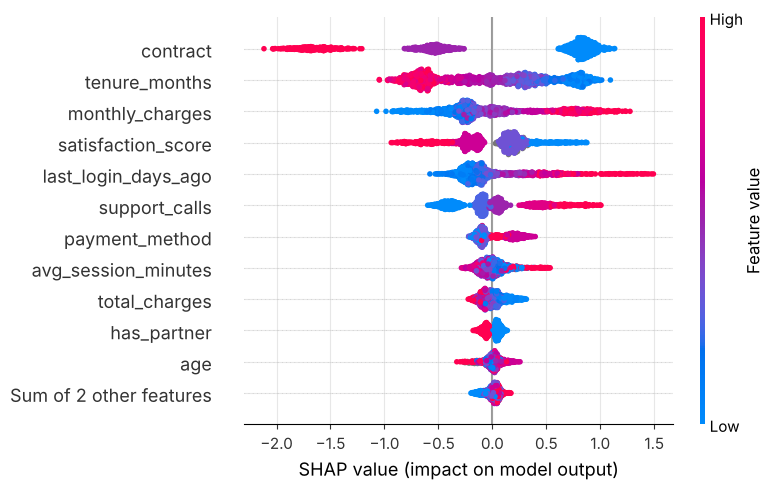

In [12]:
shap.plots.beeswarm(sv, max_display=12, show=False); plt.gcf().set_size_inches(8, 5); plt.tight_layout(); plt.show()

Reading it: high `support_calls` (red) → positive SHAP (more churn); high `tenure_months` (red) → negative SHAP (less churn); `age`, `region`, `avg_session_minutes` sit near zero. ✅ Matches the true mechanism.

**Dependence plot** — SHAP value vs feature value, coloured by the strongest interacting feature:

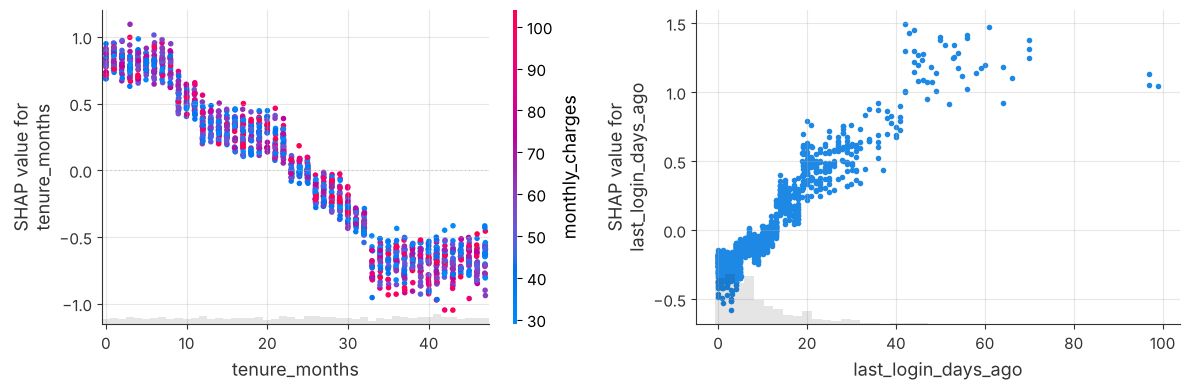

In [13]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
shap.plots.scatter(sv[:, "tenure_months"], color=sv[:, "monthly_charges"], ax=ax[0], show=False)
shap.plots.scatter(sv[:, "last_login_days_ago"], ax=ax[1], show=False)
plt.tight_layout(); plt.show()

Left: tenure's effect flattens after ~33–36 months, and at **low tenure the high-charge customers (red) sit a little higher** — a trace of the planted "expensive and new" interaction. Right: last-login effect caps around 40 days.

## 6. LIME — a local linear surrogate

**LIME** (Local Interpretable Model-agnostic Explanations) asks: *near this one customer*, what simple linear model mimics the black box?
1. Create many **perturbed copies** of the customer (randomly swap in values from other customers).
2. Get the black box's predictions for them.
3. **Weight** each copy by how similar it is to the original customer.
4. Fit a **weighted linear model** on "which features were kept vs swapped". Its coefficients are the explanation.

In [14]:
# 🔢 LIME from scratch (tabular, binary "kept / replaced" representation)
def lime_numpy(model, x, X_bg, n_samples=2000, kernel_width=0.75, seed=0):
    rng = np.random.default_rng(seed); d = len(x)
    Z = rng.integers(0, 2, (n_samples, d)); Z[0] = 1                    # 1 = keep customer's value, 0 = replace
    donors = X_bg.sample(n_samples, replace=True, random_state=seed).to_numpy()
    samples = np.where(Z == 1, x.to_numpy(), donors)
    preds = model.decision_function(pd.DataFrame(samples, columns=x.index))
    dist = np.sqrt(((1 - Z) ** 2).sum(1) / d)                           # fraction of features replaced
    w = np.exp(-dist ** 2 / kernel_width ** 2)                         # similar samples matter more
    A = np.column_stack([np.ones(n_samples), Z])
    W = np.sqrt(w)[:, None]
    coef = np.linalg.lstsq(A * W, preds * W.ravel(), rcond=None)[0]     # weighted least squares
    return pd.Series(coef[1:], index=x.index)

lime_expl = lime_numpy(gbm, X_test.iloc[i], X_train)
compare = pd.DataFrame({"LIME (ours)": lime_expl, "SHAP": pd.Series(sv.values[i], index=X.columns)})
compare = compare.reindex(compare["SHAP"].abs().sort_values(ascending=False).index).round(3)
print(compare.head(8))
print("\nRank agreement between LIME and SHAP (Spearman):", round(compare.corr(method="spearman").iloc[0, 1], 2))

                     LIME (ours)   SHAP
monthly_charges            0.996  0.991
contract                   0.975  0.854
tenure_months              0.843  0.838
last_login_days_ago        0.570  0.503
payment_method             0.260  0.275
satisfaction_score         0.217  0.203
total_charges              0.235  0.199
support_calls              0.106  0.101

Rank agreement between LIME and SHAP (Spearman): 0.98


LIME and SHAP broadly agree on the top drivers. LIME is fast and intuitive but **unstable** (results change with the random seed and the kernel width) and has no additivity guarantee; SHAP has the theory but costs more for non-tree models. (The `lime` package implements the full method.)

## 7. Pitfalls — read this before presenting explanations

1. **Explanations describe the *model*, not the world.** "Electronic check → higher churn" doesn't mean switching a customer's payment method will keep them. That's a **causal** question — it needs experiments (A/B tests) or causal inference (see `Probability_Statistics_Notes.md` Part 10).
2. **Correlated features** split or swap credit (Section 3) and make PDPs evaluate impossible data points (Section 4).
3. **A bad model has meaningful-looking explanations.** Check performance first.
4. **Base value matters.** SHAP values are relative to the background/average prediction; change the background and the numbers change.
5. **Log-odds vs probability.** Tree SHAP for classifiers is usually in log-odds; effects aren't additive in probability.
6. **Use explanations to debug.** A top feature that shouldn't be there (an ID, a timestamp, `cancellation_reason`) is a leakage alarm:

In [15]:
# Leakage detector demo: add the leaky column back and see it dominate every explanation
leaky = X_train.assign(reason_filled=df.loc[X_train.index, "churned"].values * 1.0)   # stands in for cancellation_reason
leaky_te = X_test.assign(reason_filled=df.loc[X_test.index, "churned"].values * 1.0)
m_leak = HistGradientBoostingClassifier(random_state=0).fit(leaky, y_train)
r = permutation_importance(m_leak, leaky_te, y_test, scoring="roc_auc", n_repeats=3, random_state=0)
top = pd.Series(r.importances_mean, index=leaky.columns).sort_values(ascending=False)
print(f"test AUC with leak: {roc_auc_score(y_test, m_leak.predict_proba(leaky_te)[:, 1]):.3f}  ← too good to be true")
print(top.head(3).round(3))

test AUC with leak: 1.000  ← too good to be true
reason_filled    0.497
age              0.000
plan             0.000
dtype: float64


## 8. Which method when?

| Need | Use |
|---|---|
| A model that is itself explainable | logistic regression / small tree / GAM-style models |
| "Which features matter overall?" | permutation importance (held-out data); mean \|SHAP\| |
| "How does the prediction change with X?" | PDP + ICE (ALE if features are correlated); SHAP dependence plots |
| "Why this prediction?" | SHAP waterfall (TreeSHAP for trees); LIME for a quick look |
| "What would change the decision?" | counterfactual explanations ("if contract were one-year, risk would drop to 18%") |

## Key takeaways
- Global (model behaviour) vs local (one prediction); glass-box vs model-agnostic.
- **Permutation importance:** shuffle a column, measure the drop — on held-out data.
- **PDP/ICE:** set a feature to each value, average predictions; diverging ICE lines = interactions.
- **Shapley/SHAP:** average marginal contribution over all feature orderings; additive and fair; TreeSHAP makes it fast for trees.
- **LIME:** local weighted linear surrogate; quick but unstable.
- Explanations ≠ causation; correlated features distort all methods; use explanations to catch leakage.

## Exercises
1. Write a **counterfactual** search: for the riskiest customer, try each alternative `contract` and `payment_method` value and report the new churn probability.
2. Group `tenure_months` and `total_charges` and permute them **together** (same shuffled row order). Is the group's importance larger than the sum of the individual importances?
3. Compute exact Shapley values for the same customer using **probability** instead of log-odds (`predict_proba`). Do the rankings change?

In [16]:
# Exercise 1 — solution
x0 = X_test.iloc[[i]]; p0 = gbm.predict_proba(x0)[0, 1]
print(f"current: {cat_maps['contract'][x0['contract'].iloc[0]]}, {cat_maps['payment_method'][x0['payment_method'].iloc[0]]} → {p0:.2f}")
for col in ["contract", "payment_method"]:
    for code, label in cat_maps[col].items():
        xc = x0.copy(); xc[col] = code
        print(f"  if {col} = {label:17s} → churn probability {gbm.predict_proba(xc)[0, 1]:.2f}")

current: month-to-month, electronic check → 0.93
  if contract = month-to-month    → churn probability 0.93
  if contract = one-year          → churn probability 0.76
  if contract = two-year          → churn probability 0.59
  if payment_method = bank transfer     → churn probability 0.89
  if payment_method = credit card       → churn probability 0.89
  if payment_method = electronic check  → churn probability 0.93
  if payment_method = mailed check      → churn probability 0.91


In [17]:
# Exercise 2 — solution
def group_importance(model, X_df, y_true, cols, n_repeats=5, seed=0):
    rng = np.random.default_rng(seed); base = roc_auc_score(y_true, model.predict_proba(X_df)[:, 1]); drops = []
    for _ in range(n_repeats):
        Xp = X_df.copy(); perm = rng.permutation(len(Xp))
        Xp[cols] = Xp[cols].to_numpy()[perm]          # same permutation for every column in the group
        drops.append(base - roc_auc_score(y_true, model.predict_proba(Xp)[:, 1]))
    return np.mean(drops)
single = {c: group_importance(gbm, X_test, y_test, [c]) for c in ["tenure_months", "total_charges"]}
print({k: round(float(v), 4) for k, v in single.items()}, "sum:", round(float(sum(single.values())), 4))
print("together:", round(group_importance(gbm, X_test, y_test, ["tenure_months", "total_charges"]), 4))

{'tenure_months': 0.0532, 'total_charges': 0.0024} sum: 0.0557
together: 0.0644


**Next:** [11 · Gradient Boosting in Practice](11_gradient_boosting_in_practice.ipynb) — XGBoost, LightGBM and CatBoost, and the settings that matter.

*Going deeper / interview prep:* `ML_Interview_Notes.md` §2.8 (interpretability) · `Probability_Statistics_Notes.md` Part 10 (causal inference — why explanations aren't causes) · `ML_System_Design_Notes.md` Part 6 (responsible ML) · code: `ml_from_scratch_part2.py` → `permutation_importance`.